# Tugas Praktikum 6: Clustering (Advance)

Intifada Afkar Lazain Muhammad(5054251029)


## 0. Import library

In [26]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, rand_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Unduh dan import dataset

In [27]:
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
data = pd.read_csv(url)
data.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [28]:
print("Shape:", data.shape)

Shape: (344, 8)


In [29]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


Dataset berisi 344 baris dan 8 kolom. Keempat kolom numerik (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g) masing-masing punya 342 nilai terisi, jadi 2 baris kosong. Kolom sex punya 333 nilai terisi (11 kosong), dan species tidak punya nilai kosong.

## 2. Eksplorasi dan pembersihan data

In [30]:
data.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [31]:
fitur = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# Hapus baris yang kosong pada salah satu dari 4 kolom numerik ATAU kolom species
df_clean = data.dropna(subset=fitur + ["species"]).reset_index(drop=True)

print("Jumlah baris sebelum pembersihan:", len(data))
print("Jumlah baris sesudah pembersihan:", len(df_clean))
print("Baris yang dihapus              :", len(data) - len(df_clean))
print()
print("Sisa nilai kosong sesudah pembersihan:")
print(df_clean.isna().sum())

Jumlah baris sebelum pembersihan: 344
Jumlah baris sesudah pembersihan: 342
Baris yang dihapus              : 2

Sisa nilai kosong sesudah pembersihan:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
year                 0
dtype: int64


In [32]:
print("Jumlah data per spesies (sesudah pembersihan):")
df_clean["species"].value_counts()

Jumlah data per spesies (sesudah pembersihan):


,count
species,
Adelie,151
Gentoo,123
Chinstrap,68


In [33]:
df_clean[fitur].describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Dua baris yang dihapus adalah baris yang keempat kolom numeriknya kosong sekaligus. Data bersih tersisa 342 baris, terdiri dari 151 Adelie, 123 Gentoo, dan 68 Chinstrap. Kolom sex masih punya 9 nilai kosong, tetapi kolom ini tidak dipakai, jadi barisnya dibiarkan.

Skala antar kolom sangat berbeda. body_mass_g berkisar dari 2700 sampai 6300 gram dengan standar deviasi sekitar 802, sedangkan bill_depth_mm hanya dari 13.1 sampai 21.5 mm dengan standar deviasi sekitar 1.97. Tanpa standardisasi, body_mass_g akan mendominasi perhitungan jarak.

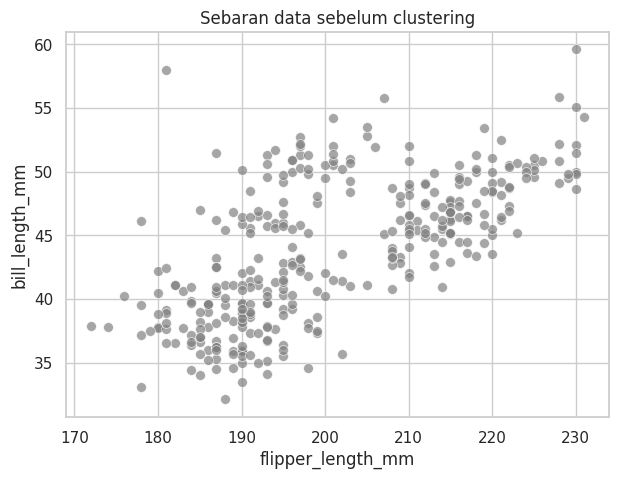

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="flipper_length_mm", y="bill_length_mm",
                color="gray", s=50, alpha=0.7)
plt.title("Sebaran data sebelum clustering")
plt.xlabel("flipper_length_mm")
plt.ylabel("bill_length_mm")
plt.show()

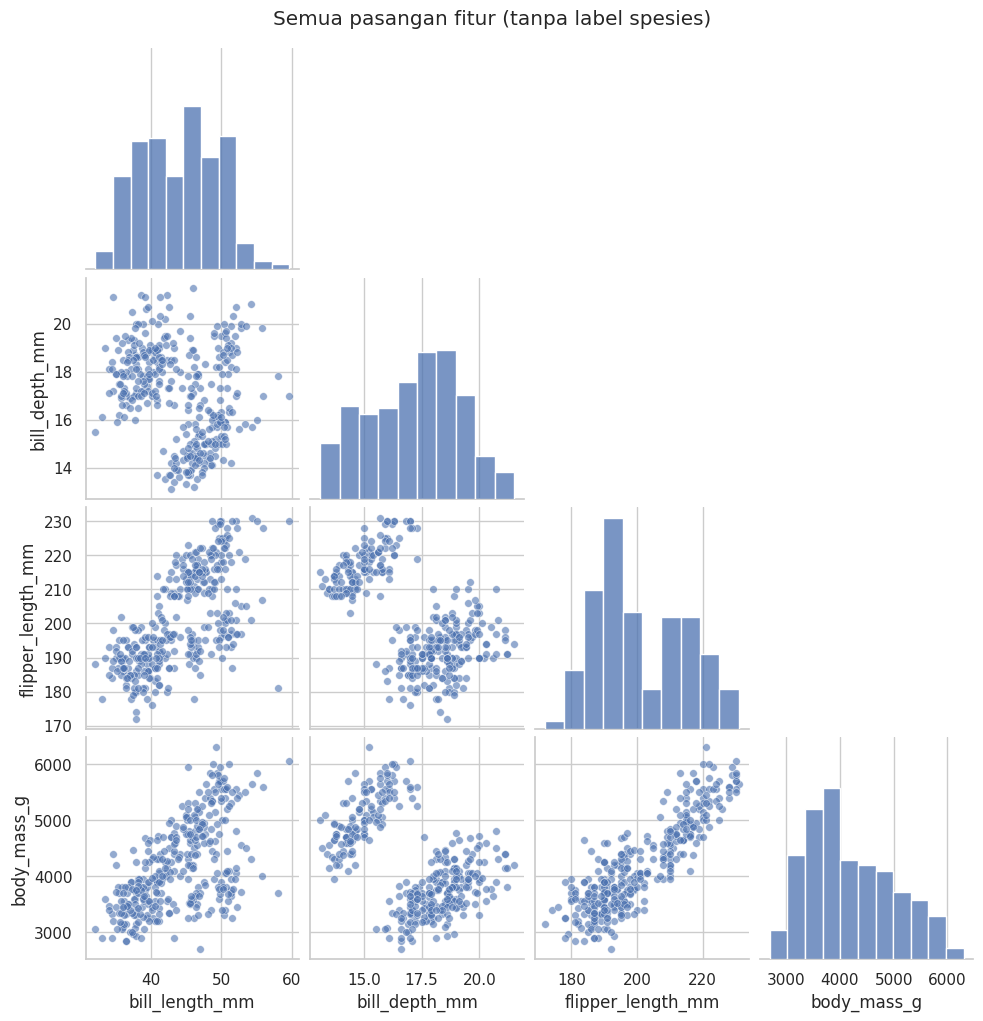

In [35]:
g = sns.pairplot(df_clean, vars=fitur, corner=True,
                 plot_kws={"alpha": 0.6, "s": 30})
g.figure.suptitle("Semua pasangan fitur (tanpa label spesies)", y=1.02)
plt.show()

Pada scatter plot flipper_length_mm terhadap bill_length_mm, satu kelompok di sisi kanan (sirip sekitar 205 mm ke atas) terlihat terpisah dari sisanya. Di sisi kiri titik-titik saling menumpuk dan sulit dipisahkan dengan mata. Pairplot menampilkan keenam pasangan fitur tanpa label spesies, seperti yang akan "dilihat" algoritma clustering.

## 3. Standardisasi data

In [36]:
X_raw = df_clean[fitur]          # matriks fitur (DataFrame)
y = df_clean["species"]         # label pembanding, TIDAK dipakai saat clustering

scaler = StandardScaler()
X = scaler.fit_transform(X_raw) # array numpy hasil z-score

print("X shape:", X.shape)
print("Rata-rata tiap kolom :", X.mean(axis=0).round(6))
print("Std tiap kolom       :", X.std(axis=0).round(6))

X shape: (342, 4)
Rata-rata tiap kolom : [ 0.  0. -0.  0.]
Std tiap kolom       : [1. 1. 1. 1.]


Setelah z-score, rata-rata tiap kolom 0 dan standar deviasinya 1. Semua algoritma di bawah dijalankan pada X ini.

## 4. Penerapan algoritma

Fungsi di bawah dipakai untuk semua scatter plot. Sumbunya memakai nilai asli flipper_length_mm dan bill_length_mm supaya mudah dibaca, sedangkan label kluster tetap berasal dari X yang sudah distandardisasi. Titik noise DBSCAN (label -1) digambar hitam dengan marker x.

In [37]:
# Sumbu scatter plot memakai nilai asli (mm) supaya mudah dibaca.
# Label kluster tetap berasal dari X yang sudah distandardisasi.
px = df_clean["flipper_length_mm"].to_numpy()
py = df_clean["bill_length_mm"].to_numpy()

def plot_kluster(ax, label, judul):
    """Satu warna untuk tiap kluster. Noise DBSCAN (label -1) hitam, marker x."""
    palet = plt.cm.tab10.colors
    warna_ke = 0
    for c in sorted(set(label)):
        mask = label == c
        if c == -1:
            ax.scatter(px[mask], py[mask], c="black", marker="x", s=40,
                       label=f"Noise ({mask.sum()})")
        else:
            ax.scatter(px[mask], py[mask], color=palet[warna_ke % 10], s=40,
                       alpha=0.8, edgecolor="white", linewidth=0.5,
                       label=f"Kluster {c} ({mask.sum()})")
            warna_ke += 1
    ax.set_title(judul)
    ax.set_xlabel("flipper_length_mm")
    ax.set_ylabel("bill_length_mm")
    ax.legend(fontsize=8)

### 4.1 Agglomerative Clustering

Linkage yang dipakai adalah ward, yaitu menggabungkan dua kluster yang menambah variansi di dalam kluster paling sedikit. Jumlah kluster ditetapkan 3.

In [38]:
LINKAGE = "ward"   # jenis linkage yang dipakai

agg = AgglomerativeClustering(n_clusters=3, linkage=LINKAGE)
agg_labels = agg.fit_predict(X)
print("Linkage:", LINKAGE)
print("Ukuran kluster:", np.bincount(agg_labels))

Linkage: ward
Ukuran kluster: [162 123  57]


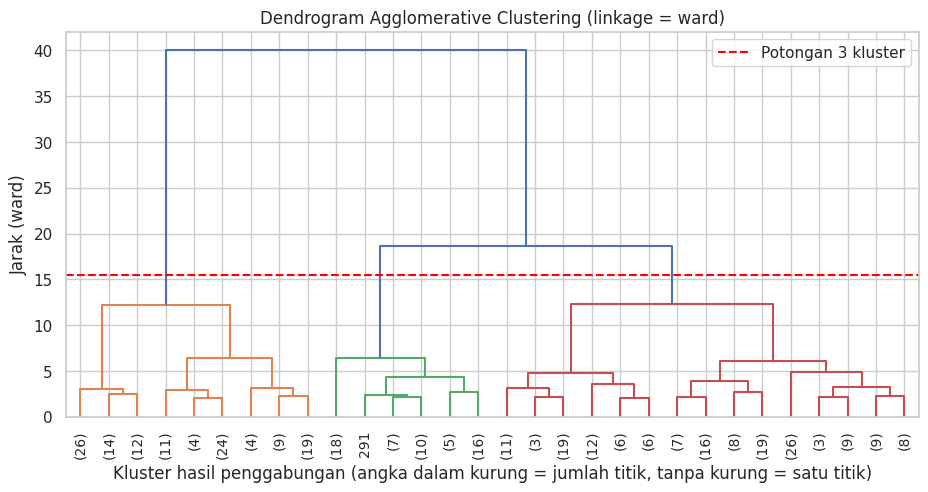

ARI scipy vs sklearn: 1.0


In [39]:
Z = linkage(X, method=LINKAGE)

# Tinggi potong yang menghasilkan tepat 3 kluster
# (di antara penggabungan ke-(n-3) dan ke-(n-2))
cut = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90,
           show_leaf_counts=True, color_threshold=cut)
plt.axhline(cut, color="red", linestyle="--", label="Potongan 3 kluster")
plt.title(f"Dendrogram Agglomerative Clustering (linkage = {LINKAGE})")
plt.xlabel("Kluster hasil penggabungan (angka dalam kurung = jumlah titik, tanpa kurung = satu titik)")
plt.ylabel("Jarak (ward)")
plt.legend()
plt.show()

# Cek: potongan scipy harus sama dengan hasil sklearn
cek = fcluster(Z, t=3, criterion="maxclust")
print("ARI scipy vs sklearn:", adjusted_rand_score(cek, agg_labels))

Penggabungan terakhir pada dendrogram terjadi di jarak sekitar 40 dan memisahkan satu cabang berisi 123 titik dari sisanya. Garis merah putus-putus di jarak sekitar 15 memotong dendrogram menjadi 3 kluster berukuran 162, 123, dan 57. Hasil potongan scipy sama dengan hasil AgglomerativeClustering (ARI = 1.0).

### 4.2 DBSCAN

Percobaan dimulai dari eps 0.5 dengan MinPts (min_samples) 5, lalu eps divariasikan untuk melihat jumlah kluster dan titik noise.

In [40]:
dbscan_labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X)

def ringkas_dbscan(label):
    n_k = len(set(label)) - (1 if -1 in label else 0)
    return n_k, int((label == -1).sum())

n_k, n_noise = ringkas_dbscan(dbscan_labels)
print(f"eps=0.5, MinPts=5 -> {n_k} kluster, {n_noise} titik noise")

eps=0.5, MinPts=5 -> 4 kluster, 69 titik noise


In [41]:
eps_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
baris, label_eps = [], {}
for eps in eps_list:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    label_eps[eps] = lab
    n_k, n_noise = ringkas_dbscan(lab)
    baris.append({"eps": eps, "MinPts": 5, "jumlah_kluster": n_k,
                  "titik_noise": n_noise,
                  "noise_%": round(100 * n_noise / len(X), 1)})

tabel_dbscan = pd.DataFrame(baris)
tabel_dbscan

,eps,MinPts,jumlah_kluster,titik_noise,noise_%
0,0.3,5,4,317,92.7
1,0.4,5,10,171,50.0
2,0.5,5,4,69,20.2
3,0.6,5,2,33,9.6
4,0.7,5,2,16,4.7
5,0.8,5,2,5,1.5
6,0.9,5,2,2,0.6
7,1.0,5,2,1,0.3


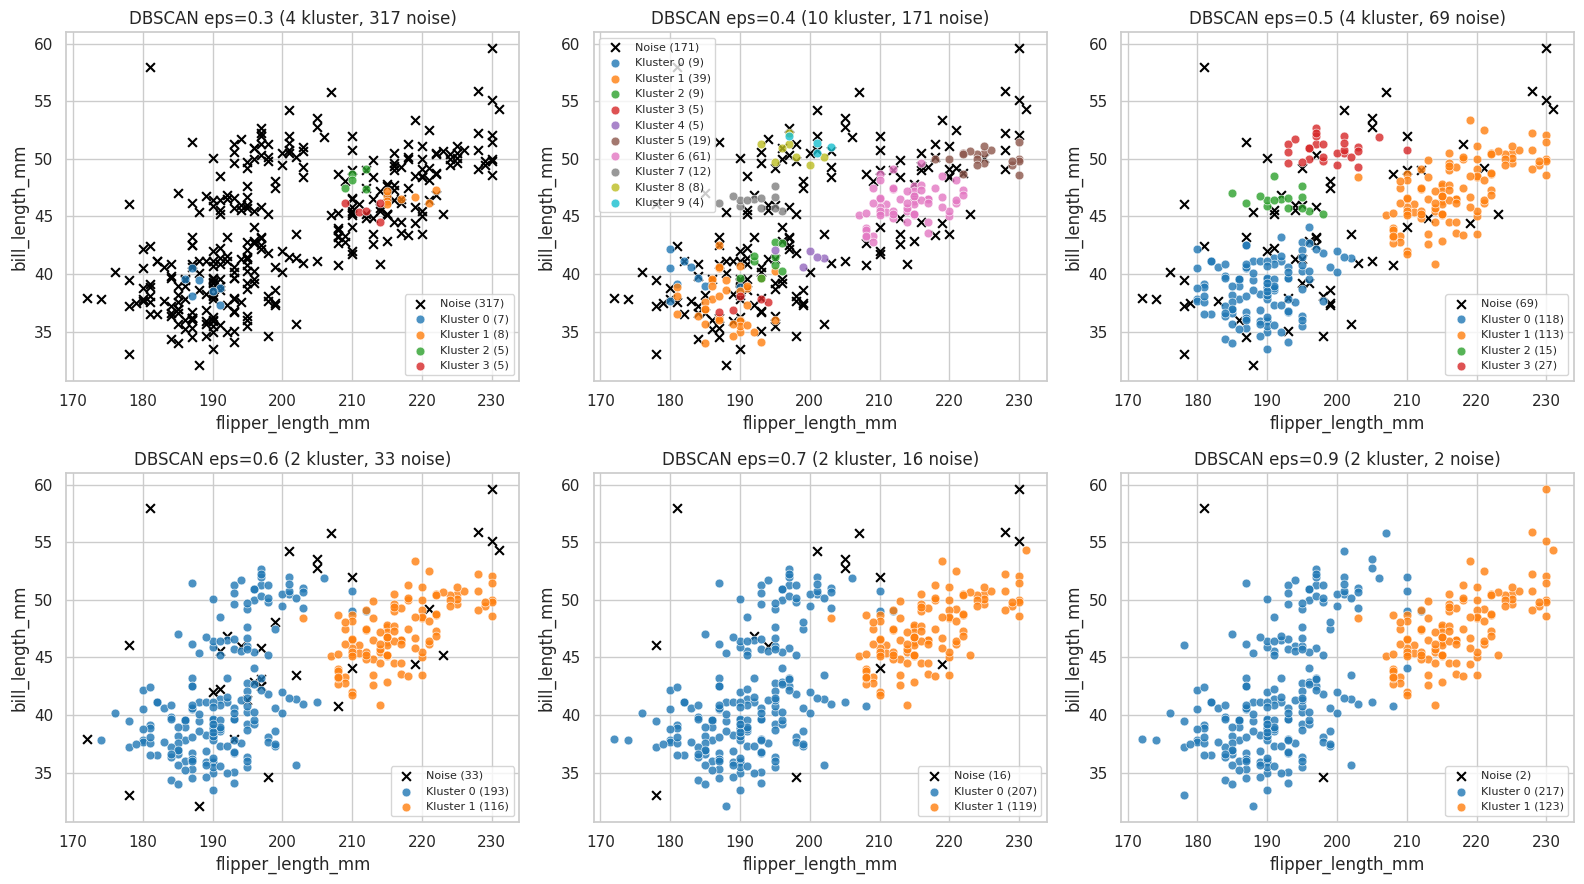

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, eps in zip(axes.ravel(), [0.3, 0.4, 0.5, 0.6, 0.7, 0.9]):
    n_k, n_noise = ringkas_dbscan(label_eps[eps])
    plot_kluster(ax, label_eps[eps], f"DBSCAN eps={eps} ({n_k} kluster, {n_noise} noise)")
plt.tight_layout()
plt.show()

Pada eps 0.5 DBSCAN menemukan 4 kluster dan menandai 69 titik (20.2%) sebagai noise. Eps yang lebih kecil membuat hampir semua titik menjadi noise: 317 titik (92.7%) pada eps 0.3, dan pada eps 0.4 muncul 10 kluster kecil dengan 171 noise. Mulai eps 0.6 hasilnya tinggal 2 kluster, dan noise terus turun: 33 titik pada eps 0.6, 16 pada 0.7, 5 pada 0.8, 2 pada 0.9, dan 1 pada 1.0. Tidak ada eps dalam rentang ini yang menghasilkan tepat 3 kluster.

Pada eps 0.7 dua kluster yang terbentuk adalah Gentoo (119 titik) dan gabungan Adelie dengan Chinstrap (207 titik). Kedua spesies itu tumpang tindih di ruang fitur, sehingga DBSCAN menganggapnya satu daerah padat.

### 4.3 Gaussian Mixture Models

Memakai 3 komponen, kovarians penuh (default), dan random_state 42.

In [43]:
gmm = GaussianMixture(n_components=3, random_state=RANDOM_STATE)
gmm_labels = gmm.fit(X).predict(X)
print("Ukuran kluster:", np.bincount(gmm_labels))
print("Bobot komponen:", gmm.weights_.round(3))
print("Konvergen     :", gmm.converged_)

Ukuran kluster: [ 67 123 152]
Bobot komponen: [0.199 0.36  0.442]
Konvergen     : True


GMM konvergen dan menghasilkan kluster berukuran 67, 123, dan 152 (bobot komponen 0.199, 0.360, 0.442). Ukuran ini paling dekat dengan jumlah asli per spesies (68, 123, 151) dibanding algoritma lain.

### 4.4 Spectral Clustering

Memakai 3 kluster dan affinity nearest_neighbors dengan n_neighbors 15.

In [44]:
# Graf tetangga terdekat terpecah menjadi beberapa komponen terhubung, sehingga sklearn
# memberi peringatan. Hasilnya tetap 3 kluster, jadi peringatan itu disembunyikan.
warnings.filterwarnings("ignore", message="Graph is not fully connected")

spectral = SpectralClustering(n_clusters=3, affinity="nearest_neighbors",
                              n_neighbors=15, random_state=RANDOM_STATE)
spectral_labels = spectral.fit_predict(X)
print("Ukuran kluster:", np.bincount(spectral_labels))

Ukuran kluster: [159 123  60]


### 4.5 Scatter plot hasil tiap algoritma

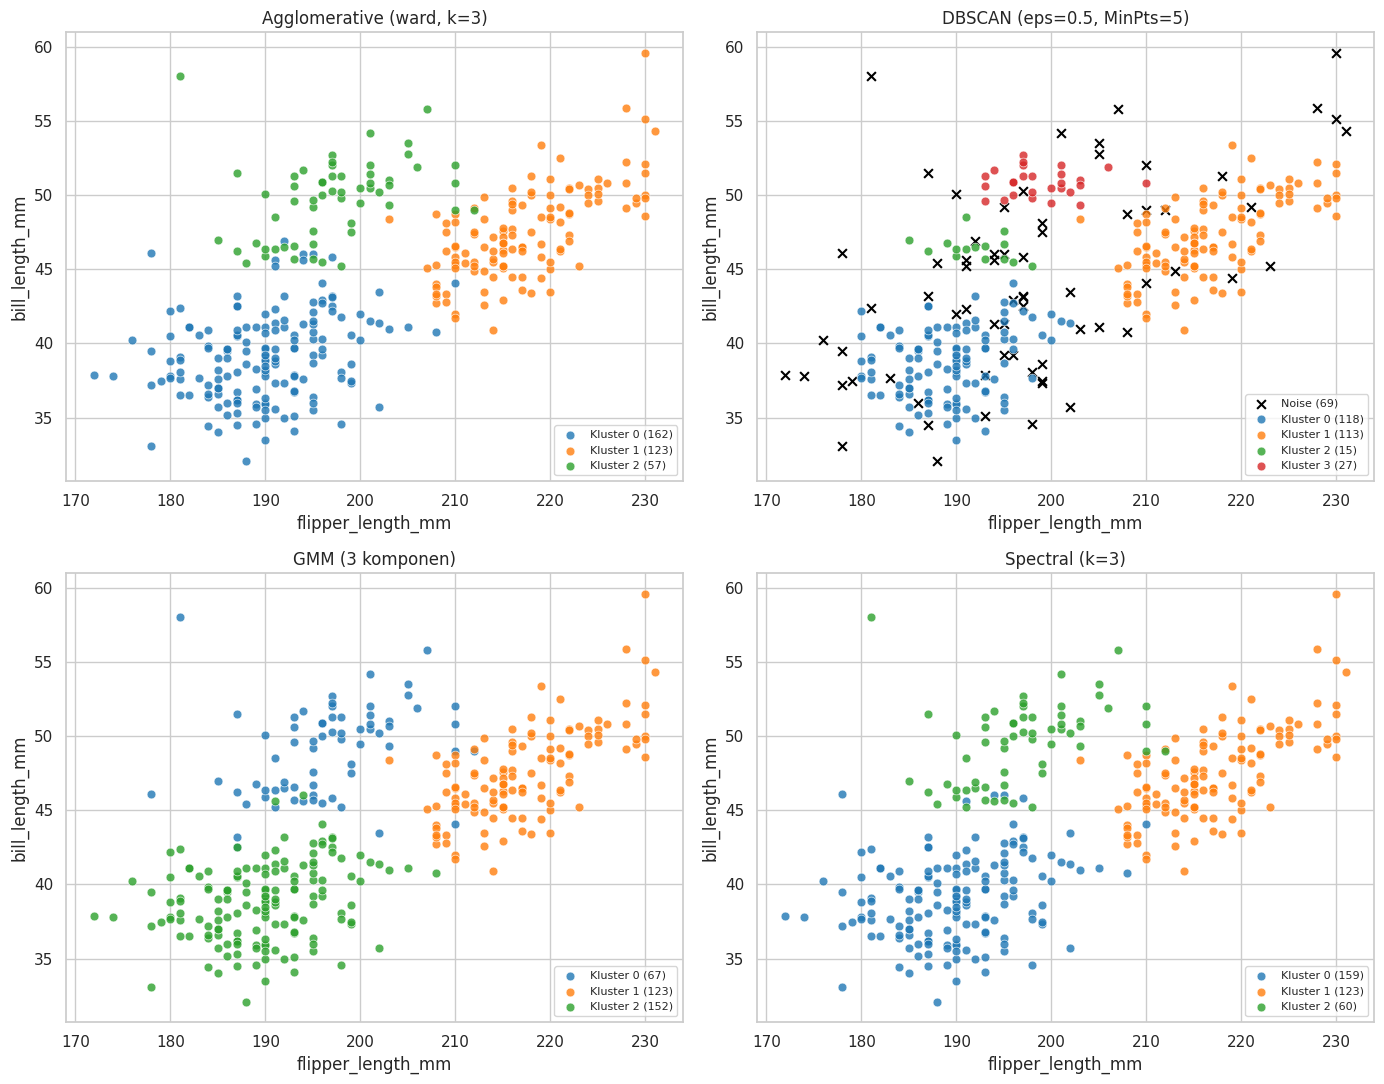

In [45]:
hasil = {
    "Agglomerative (ward, k=3)": agg_labels,
    "DBSCAN (eps=0.5, MinPts=5)": dbscan_labels,
    "GMM (3 komponen)": gmm_labels,
    "Spectral (k=3)": spectral_labels,
}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (nama, lab) in zip(axes.ravel(), hasil.items()):
    plot_kluster(ax, lab, nama)
plt.tight_layout()
plt.show()

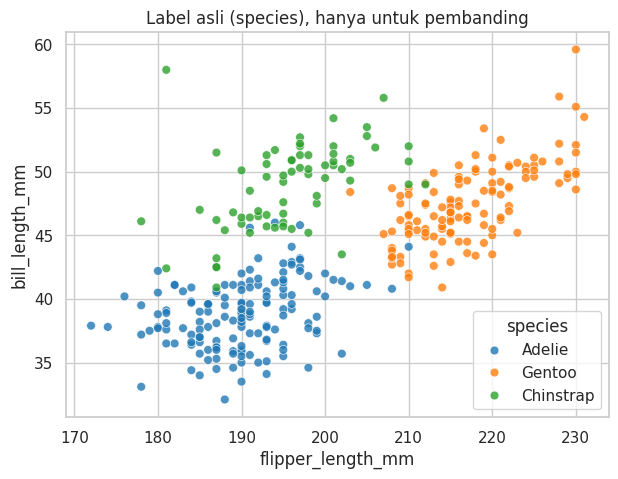


Agglomerative (ward, k=3)
kluster      0    1   2
species                
Adelie     151    0   0
Chinstrap   11    0  57
Gentoo       0  123   0

DBSCAN (eps=0.5, MinPts=5)
kluster    -1    0    1   2   3
species                        
Adelie     36  115    0   0   0
Chinstrap  23    3    0  15  27
Gentoo     10    0  113   0   0

GMM (3 komponen)
kluster     0    1    2
species                
Adelie      2    0  149
Chinstrap  65    0    3
Gentoo      0  123    0

Spectral (k=3)
kluster      0    1   2
species                
Adelie     151    0   0
Chinstrap    8    0  60
Gentoo       0  123   0


In [46]:
# Pembanding: sebaran spesies asli pada sumbu yang sama
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=px, y=py, hue=y, palette="tab10", s=40, alpha=0.8, ax=ax)
ax.set_title("Label asli (species), hanya untuk pembanding")
ax.set_xlabel("flipper_length_mm")
ax.set_ylabel("bill_length_mm")
plt.show()

for nama, lab in hasil.items():
    print(f"\n{nama}")
    print(pd.crosstab(y, lab, rownames=["species"], colnames=["kluster"]))

Warna dan nomor kluster tidak bisa dibandingkan antar algoritma, karena label kluster ditentukan acak (kluster 0 di satu algoritma belum tentu sama dengan kluster 0 di algoritma lain).

Gentoo terpisah rapi sebagai satu kluster di keempat algoritma. Perbedaannya ada pada Adelie dan Chinstrap yang saling tumpang tindih. Tabel silang dengan species menunjukkan:

- Agglomerative menempatkan 11 Chinstrap ke kluster Adelie.
- Spectral menempatkan 8 Chinstrap ke kluster Adelie.
- GMM salah menempatkan 5 titik: 2 Adelie masuk kluster Chinstrap dan 3 Chinstrap masuk kluster Adelie.
- DBSCAN eps 0.5 memecah Chinstrap menjadi dua kluster (15 dan 27 titik), menyisakan 3 Chinstrap di kluster Adelie, dan membuang 69 titik sebagai noise (36 Adelie, 23 Chinstrap, 10 Gentoo).

## 5. Evaluasi hasil clustering

Silhouette untuk DBSCAN dihitung tanpa titik noise, dan jumlah titik yang dibuang dicatat di kolom Noise dibuang. Rand Index dan NMI dihitung terhadap species pada seluruh 342 titik, dengan noise DBSCAN dianggap satu kelompok (label -1). Adjusted Rand Index (ARI) ditambahkan karena Rand Index tidak dikoreksi terhadap kebetulan. DBSCAN dievaluasi pada dua pengaturan: eps 0.5 (awal) dan eps 0.7 (noise sudah sedikit).

In [47]:
def evaluasi(label, nama):
    mask = label != -1                      # buang noise (hanya relevan untuk DBSCAN)
    n_buang = int((~mask).sum())
    n_k = len(np.unique(label[mask]))
    sil = silhouette_score(X[mask], label[mask]) if n_k > 1 else np.nan
    return {
        "Algoritma": nama,
        "Jumlah kluster": n_k,
        "Noise dibuang": n_buang,
        "Silhouette": sil,
        # Rand Index & NMI dihitung pada SEMUA titik; noise DBSCAN dianggap satu grup (-1)
        "Rand Index": rand_score(y, label),
        "ARI": adjusted_rand_score(y, label),
        "NMI": normalized_mutual_info_score(y, label),
    }

label_eval = {
    "Agglomerative (ward)": agg_labels,
    "DBSCAN (eps=0.5)": dbscan_labels,
    "DBSCAN (eps=0.7)": label_eps[0.7],
    "GMM": gmm_labels,
    "Spectral": spectral_labels,
}
tabel_eval = pd.DataFrame([evaluasi(l, n) for n, l in label_eval.items()]).set_index("Algoritma")
tabel_eval.round(3)

,Jumlah kluster,Noise dibuang,Silhouette,Rand Index,ARI,NMI
Algoritma,,,,,,
Agglomerative (ward),3,0,0.454,0.961,0.916,0.901
DBSCAN (eps=0.5),4,69,0.424,0.853,0.663,0.663
DBSCAN (eps=0.7),2,16,0.551,0.821,0.639,0.683
GMM,3,0,0.455,0.982,0.960,0.935
Spectral,3,0,0.457,0.971,0.938,0.921


Silhouette ketiga algoritma dengan 3 kluster hampir sama, yaitu antara 0.454 dan 0.457, jadi selisih sekecil itu tidak cukup untuk memilih pemenang. DBSCAN eps 0.5 mendapat 0.424 setelah 69 titik dibuang. DBSCAN eps 0.7 mendapat 0.551, yang tertinggi, tetapi skor itu berasal dari 2 kluster yang terpisah jelas dan pembuangan 16 titik sulit. Kecocokannya dengan species rendah (NMI 0.683).

Pada metrik eksternal GMM paling tinggi (Rand Index 0.982, ARI 0.960, NMI 0.935), disusul Spectral (0.971, 0.938, 0.921) dan Agglomerative (0.961, 0.916, 0.901). DBSCAN jauh di bawahnya: Rand Index 0.853 dan NMI 0.663 untuk eps 0.5, terutama karena noise dan Chinstrap yang pecah menjadi dua kluster.

Uji kestabilan di bawah menjalankan ulang tiap algoritma pada tiga subsampel acak 90% data (307 dari 342 baris). Subsampel yang sama dipakai untuk semua algoritma, dan standardisasi tidak diulang (baris diambil dari X yang sama). Hasilnya dibandingkan dengan hasil data penuh pada baris yang sama memakai ARI dan NMI, dengan nilai 1 berarti pengelompokan identik.

In [48]:
model = {
    "Agglomerative (ward)": lambda A: AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(A),
    "DBSCAN (eps=0.5)": lambda A: DBSCAN(eps=0.5, min_samples=5).fit_predict(A),
    "DBSCAN (eps=0.7)": lambda A: DBSCAN(eps=0.7, min_samples=5).fit_predict(A),
    "GMM": lambda A: GaussianMixture(n_components=3, random_state=RANDOM_STATE).fit_predict(A),
    "Spectral": lambda A: SpectralClustering(n_clusters=3, affinity="nearest_neighbors",
                                             n_neighbors=15, random_state=RANDOM_STATE).fit_predict(A),
}

# Hasil pada data penuh = label_eval. Tiga subsampel 90% yang sama dipakai untuk semua algoritma.
rng = np.random.default_rng(RANDOM_STATE)
n_sub = int(0.9 * len(X))
subsampel = [np.sort(rng.choice(len(X), size=n_sub, replace=False)) for _ in range(3)]

baris = []
for nama, fungsi in model.items():
    ari_run, nmi_run = [], []
    for idx in subsampel:
        lab_sub = fungsi(X[idx])
        lab_penuh = label_eval[nama][idx]      # label data penuh pada baris yang sama
        ari_run.append(adjusted_rand_score(lab_penuh, lab_sub))
        nmi_run.append(normalized_mutual_info_score(lab_penuh, lab_sub))
    baris.append({"Algoritma": nama,
                  "ARI run 1": ari_run[0], "ARI run 2": ari_run[1], "ARI run 3": ari_run[2],
                  "ARI rata-rata": np.mean(ari_run), "NMI rata-rata": np.mean(nmi_run)})

tabel_stab = pd.DataFrame(baris).set_index("Algoritma")
print(f"Ukuran tiap subsampel: {n_sub} dari {len(X)} baris")
tabel_stab.round(3)

Ukuran tiap subsampel: 307 dari 342 baris


,ARI run 1,ARI run 2,ARI run 3,ARI rata-rata,NMI rata-rata
Algoritma,,,,,
Agglomerative (ward),0.931,0.940,0.939,0.937,0.916
DBSCAN (eps=0.5),0.912,0.891,0.942,0.915,0.910
DBSCAN (eps=0.7),1.000,0.975,0.991,0.989,0.978
GMM,1.000,0.881,1.000,0.960,0.958
Spectral,0.991,0.991,1.000,0.994,0.988


Spectral paling stabil (ARI rata-rata 0.994, NMI 0.988), disusul DBSCAN eps 0.7 (0.989 dan 0.978), GMM (0.960 dan 0.958), Agglomerative (0.937 dan 0.916), dan DBSCAN eps 0.5 (0.915 dan 0.910). Stabilitas DBSCAN eps 0.7 tinggi, tetapi hasil yang stabil itu hanya 2 kluster. GMM kurang merata antar subsampel: ARI 1.000 pada run 1 dan 3, tetapi 0.881 pada run 2.

In [49]:
ringkasan = tabel_eval.join(tabel_stab[["ARI rata-rata", "NMI rata-rata"]]
                           .rename(columns={"ARI rata-rata": "Stabilitas ARI",
                                            "NMI rata-rata": "Stabilitas NMI"}))
ringkasan.round(3)

,Jumlah kluster,Noise dibuang,Silhouette,Rand Index,ARI,NMI,Stabilitas ARI,Stabilitas NMI
Algoritma,,,,,,,,
Agglomerative (ward),3,0,0.454,0.961,0.916,0.901,0.937,0.916
DBSCAN (eps=0.5),4,69,0.424,0.853,0.663,0.663,0.915,0.910
DBSCAN (eps=0.7),2,16,0.551,0.821,0.639,0.683,0.989,0.978
GMM,3,0,0.455,0.982,0.960,0.935,0.960,0.958
Spectral,3,0,0.457,0.971,0.938,0.921,0.994,0.988


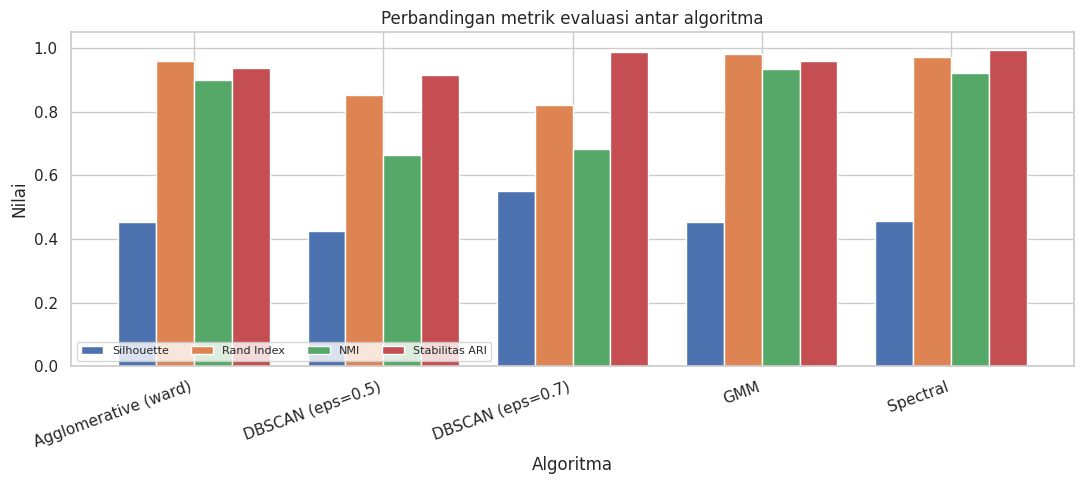

In [50]:
metrik = ["Silhouette", "Rand Index", "NMI", "Stabilitas ARI"]
ringkasan[metrik].plot(kind="bar", figsize=(11, 5), width=0.8)
plt.title("Perbandingan metrik evaluasi antar algoritma")
plt.ylabel("Nilai")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower left", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 6. Kesimpulan

GMM dengan 3 komponen paling cocok untuk dataset ini. Nilai Rand Index (0.982), ARI (0.960), dan NMI (0.935)-nya tertinggi, hanya 5 dari 342 penguin yang jatuh ke kluster yang bukan spesiesnya, dan ukuran klusternya (67, 123, 152) paling dekat dengan jumlah asli per spesies (68, 123, 151). Kelompok pada scatter plot tampak berbentuk elips dengan ukuran berbeda, dan GMM memodelkan tiap kluster dengan kovarians sendiri, sehingga sesuai dengan struktur itu. Silhouette-nya 0.455, hampir sama dengan algoritma lain, jadi pemilihan ini bertumpu pada metrik eksternal. Kestabilannya baik (ARI rata-rata 0.960), walaupun satu dari tiga subsampel menurunkannya ke 0.881.

Spectral Clustering layak sebagai pilihan kedua. Metrik eksternalnya sedikit di bawah GMM (Rand Index 0.971, NMI 0.921), tetapi paling stabil (ARI rata-rata 0.994). Agglomerative dengan linkage ward memberi hasil serupa, dengan 11 Chinstrap masuk ke kluster Adelie. DBSCAN kurang cocok. Eps harus dicari dengan coba-coba, tidak ada eps yang diuji menghasilkan 3 kluster, eps 0.5 membuang 69 titik sebagai noise, dan Silhouette tertingginya (0.551 pada eps 0.7) berasal dari hasil 2 kluster yang menggabungkan Adelie dan Chinstrap.

Perbandingan ini memakai satu dataset dengan species sebagai acuan, hanya tiga subsampel, dan satu pengaturan per algoritma (kecuali DBSCAN). Selisih kecil, misalnya antara GMM dan Spectral, belum tentu bertahan pada pengaturan lain.